# HCAID Kredietrisico: data, model en ethiek

Dit notebook onderbouwt het model achter de twee apps:

- **Schuldwijzer** (goedaardig): waarschuwt vooraf als een lening waarschijnlijk niet te dragen is, legt uit waarom, en verwijst naar hulp.
- **SnelGeld** (kwaadaardig): gebruikt dezelfde soort voorspelling om juist kwetsbare mensen een dure lening te verkopen.

**Voorspelling:** de kans dat iemand een lening niet (goed) terugbetaalt, `class = bad`. Een classificatie met een **monotoon neuraal netwerk** (eigen implementatie in `ml/monotone.py`) op 10 (Schuldwijzer) of 20 (SnelGeld) features en één outputvariabele.

Inhoud:
1. Data laden en verkennen
2. Is dit goede data? Kwaliteit en beperkingen
3. Ethisch risico in de data: bias
4. Feature-keuze voor beide apps
5. Training en evaluatie, en waarom een monotoon netwerk
6. Precision of recall? De drempel van Schuldwijzer
7. Fairness-audit
8. Explainability: globaal en lokaal
9. Wat verlaagt het risico? (counterfactuals)
10. SnelGeld: dezelfde voorspelling, omgezet in winst
11. Conclusie

In [1]:
import sys, json, warnings
from pathlib import Path
warnings.filterwarnings('ignore')
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from ml.config import (DATA_PATH, FEATURES, SCHULDWIJZER_FEATURES, SNELGELD_FEATURES,
                       SENSITIVE, DAMIAN, NUMERIC, RANDOM_STATE)
from ml.train import load_data, make_pipeline, mlp
from ml.explain import Predictor
from ml.monotone import MonotoneNNClassifier
from ml.checks import violations

sns.set_theme(style='whitegrid', context='notebook')
INK, ACC, RISK = '#0b1f33', '#00577a', '#c2410c'
pd.set_option('display.max_columns', 30)

## 1. Data laden en verkennen

**Dataset:** German Credit (Statlog), via OpenML `credit-g`. 1000 leningaanvragen bij een Duitse bank in de jaren '70, 20 kenmerken, en het label of de lening goed (`good`) of slecht (`bad`) is afgelopen.

We kozen deze dataset omdat de voorspelling (kredietrisico) direct ingrijpt in iemands leven. Daardoor zijn de ethische keuzes (privacy, bias, uitleg) concreet en voelbaar, en kun je met precies dezelfde voorspelling zowel beschermen als uitbuiten.

In [2]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
df.head()

(1000, 21)


,checking_status,duration,credit_history,purpose,credit_amount,savings_status,employment,installment_commitment,personal_status,other_parties,residence_since,property_magnitude,age,other_payment_plans,housing,existing_credits,job,num_dependents,own_telephone,foreign_worker,class
0,<0,6,critical/other existing credit,radio/tv,1169,no known savings,>=7,4,male single,none,4,real estate,67,none,own,2,skilled,1,yes,yes,good
1,0<=X<200,48,existing paid,radio/tv,5951,<100,1<=X<4,2,female div/dep/mar,none,2,real estate,22,none,own,1,skilled,1,none,yes,bad
2,no checking,12,critical/other existing credit,education,2096,<100,4<=X<7,2,male single,none,3,real estate,49,none,own,1,unskilled resident,2,none,yes,good
3,<0,42,existing paid,furniture/equipment,7882,<100,4<=X<7,2,male single,guarantor,4,life insurance,45,none,for free,1,skilled,2,none,yes,good
4,<0,24,delayed previously,new car,4870,<100,1<=X<4,3,male single,none,4,no known property,53,none,for free,2,skilled,2,none,yes,bad


In [3]:
print('Ontbrekende waarden per kolom:', int(df.isna().sum().sum()))
df['class'].value_counts(normalize=True).rename('aandeel').to_frame()

Ontbrekende waarden per kolom: 0


,aandeel
class,
good,0.7
bad,0.3


70% van de leningen ging goed, 30% niet. De klassen zijn dus ongelijk verdeeld: een model dat altijd 'good' zegt, heeft al 70% accuracy. Daarom kijken we vooral naar **ROC AUC** en naar **recall op 'bad'**, niet naar accuracy alleen.

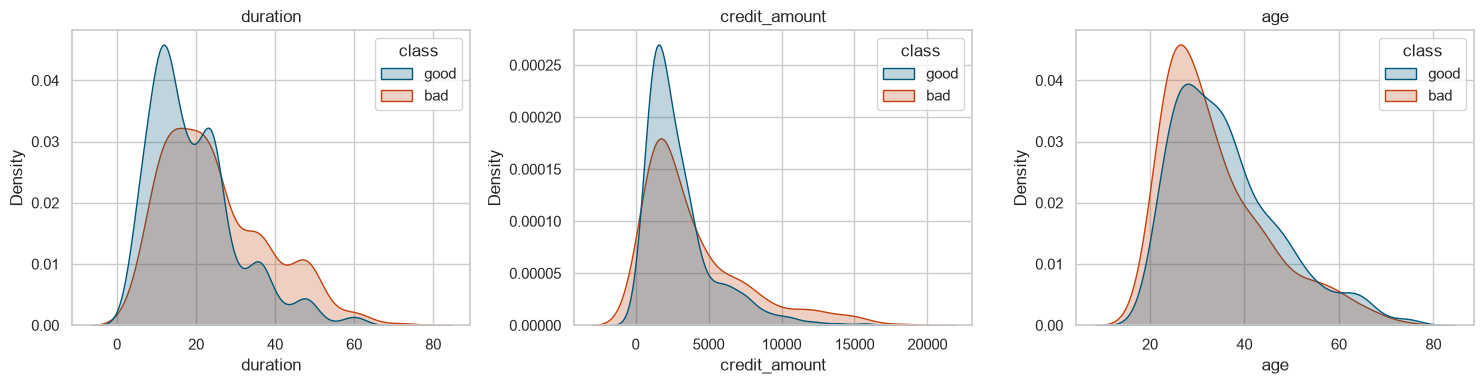

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ['duration', 'credit_amount', 'age']):
    sns.kdeplot(data=df, x=col, hue='class', common_norm=False, fill=True, ax=ax,
                palette={'good': ACC, 'bad': RISK})
    ax.set_title(col)
plt.tight_layout(); plt.show()

Langere looptijden en hogere bedragen gaan vaker mis. Jongere aanvragers komen ook vaker in de problemen. Dat laatste is meteen een eerste ethisch signaal: leeftijd is een beschermd kenmerk.

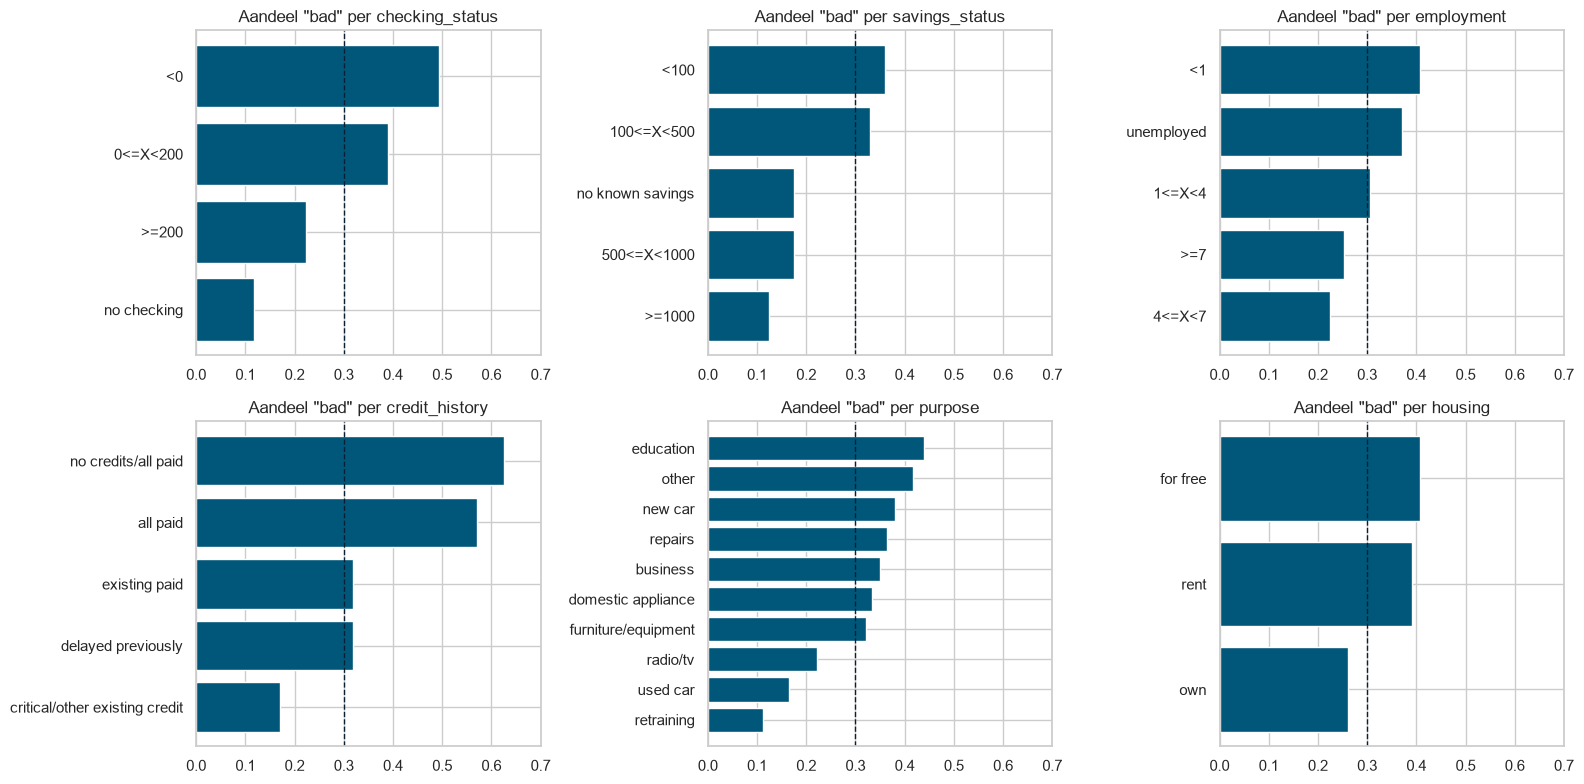

In [5]:
bad_rate = lambda s: (s == 'bad').mean()
cats = ['checking_status', 'savings_status', 'employment', 'credit_history', 'purpose', 'housing']
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, col in zip(axes.ravel(), cats):
    r = df.groupby(col)['class'].apply(bad_rate).sort_values()
    ax.barh(r.index.astype(str), r.values, color=ACC)
    ax.axvline(0.3, color=INK, ls='--', lw=1)
    ax.set_title(f'Aandeel "bad" per {col}'); ax.set_xlim(0, 0.7)
plt.tight_layout(); plt.show()

## 2. Is dit goede data? Kwaliteit en beperkingen

Goede data laat **patronen** zien die logisch zijn en passen bij de vraag. Dat geldt hier grotendeels (saldo, spaargeld, looptijd, dienstverband), maar niet overal:

| Probleem | Wat we zien | Wat we ermee doen |
|---|---|---|
| **Oud en buitenlands** | Duitsland, jaren '70, bedragen in DM | Bedragen omgerekend (1 euro = 1,95583 DM); in de app benoemd als beperking |
| **Klein** | 1000 rijen, 300 'bad' | Simpel model, sterke regularisatie, cross-validation, eerlijke foutmarge in de app |
| **Kredietverleden werkt omgekeerd** | "critical/other existing credit" heeft het *laagste* risico (17%), "all paid" het hoogste (57%) | Waarschijnlijk selectiebias: wie een kritieke rekening had, kreeg alleen na strenge controle een lening. Weggelaten uit Schuldwijzer |
| **Geslacht en burgerlijke staat in één kolom** | `personal_status`, en "female" is niet uitgesplitst | Beschermd kenmerk, weggelaten uit Schuldwijzer |
| **`foreign_worker` scheef** | 96% "yes" | Te weinig data voor de andere groep; beschermd kenmerk, weggelaten |

In [6]:
df.groupby('credit_history')['class'].apply(bad_rate).sort_values().rename('aandeel bad').to_frame()

,aandeel bad
credit_history,
critical/other existing credit,0.170648
delayed previously,0.318182
existing paid,0.318868
all paid,0.571429
no credits/all paid,0.625000


## 3. Ethisch risico in de data: bias

Hoe vaak ging het mis per beschermde groep? Als die verschillen in de data zitten, leert een model ze over, tenzij we daar bewust iets aan doen.

In [7]:
grp = pd.DataFrame({
    'geslacht': df['personal_status'].map(lambda s: 'vrouw' if s.startswith('female') else 'man'),
    'leeftijd': pd.cut(df['age'], [0, 25, 200], labels=['25 of jonger', 'ouder dan 25']),
    'buitenlandse werknemer': df['foreign_worker'],
    'bad': (df['class'] == 'bad').astype(int),
})
rows = []
for g in ['geslacht', 'leeftijd', 'buitenlandse werknemer']:
    t = grp.groupby(g, observed=True)['bad'].agg(['count', 'mean']).reset_index()
    t.columns = ['groep', 'n', 'aandeel bad']; t.insert(0, 'kenmerk', g); rows.append(t)
pd.concat(rows).round(3)

,kenmerk,groep,n,aandeel bad
0,geslacht,man,690,0.277
1,geslacht,vrouw,310,0.352
0,leeftijd,25 of jonger,190,0.421
1,leeftijd,ouder dan 25,810,0.272
0,buitenlandse werknemer,no,37,0.108
1,buitenlandse werknemer,yes,963,0.307


Vrouwen (35% bad tegen 28%) en jongeren (42% tegen 27%) kwamen in deze data vaker in betalingsproblemen. Dat kan historische en maatschappelijke oorzaken hebben (lagere inkomens, kortere dienstverbanden), maar **een lening weigeren of duurder maken op basis van geslacht of leeftijd is discriminatie**.

- Schuldwijzer gebruikt deze kenmerken daarom niet.
- SnelGeld gebruikt ze juist wel, en rekent er zelfs een opslag voor.

## 4. Feature-keuze voor beide apps

**Schuldwijzer: dataminimalisatie.** Alleen vragen wat de voorspelling echt nodig heeft, en geen beschermde kenmerken. We vergelijken drie sets met 5-voudige cross-validation (het monotone netwerk wordt in sectie 5 uitgelegd):

In [8]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.linear_model import LogisticRegression

X, y = load_data()
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
sets = {
    'Alle 20 features (SnelGeld)': SNELGELD_FEATURES,
    'Zonder geslacht, leeftijd, nationaliteit': [f for f in SNELGELD_FEATURES if f not in SENSITIVE],
    'Schuldwijzer: 10 features, ook zonder kredietverleden': SCHULDWIJZER_FEATURES,
}
res = []
for name, feats in sets.items():
    for mname, m in [('Monotoon neuraal netwerk', MonotoneNNClassifier(feats, hidden=4, alpha=0.01)),
                     ('Logistische regressie', make_pipeline(feats, LogisticRegression(max_iter=2000, C=0.3)))]:
        s = cross_val_score(m, X[feats], y, cv=cv, scoring='roc_auc')
        res.append({'featureset': name, 'model': mname, 'n features': len(feats),
                    'AUC (cv)': round(s.mean(), 3), 'std': round(s.std(), 3)})
pd.DataFrame(res)

,featureset,model,n features,AUC (cv),std
0,Alle 20 features (SnelGeld),Monotoon neuraal netwerk,20,0.796,0.021
1,Alle 20 features (SnelGeld),Logistische regressie,20,0.789,0.019
2,"Zonder geslacht, leeftijd, nationaliteit",Monotoon neuraal netwerk,17,0.791,0.023
3,"Zonder geslacht, leeftijd, nationaliteit",Logistische regressie,17,0.781,0.022
4,"Schuldwijzer: 10 features, ook zonder kredietv...",Monotoon neuraal netwerk,10,0.779,0.023
5,"Schuldwijzer: 10 features, ook zonder kredietv...",Logistische regressie,10,0.770,0.023


**Conclusie:** met de helft van de vragen en zonder beschermde kenmerken presteert het model vrijwel even goed. De verschillen vallen binnen de standaardafwijking. Privacy en eerlijkheid kosten hier dus nauwelijks nauwkeurigheid: een sterk argument voor het ontwerp van Schuldwijzer.

**SnelGeld** vraagt alles, ook gegevens die het model niet nodig heeft (naam, e-mail, telefoon, contacten), omdat die commercieel waardevol zijn.

## 5. Training en evaluatie, en waarom een monotoon netwerk

**Het probleem met een gewoon netwerk.** Onze eerste versie gebruikte een gewone `MLPClassifier`. Die volgt elke eigenaardigheid in de data. Een beoordelaar die met de schuifjes speelt, ziet dan dingen als "geen werk" met een lager risico dan "korter dan 1 jaar in dienst", of een langere looptijd die veiliger lijkt. Dat is onlogisch, niet uit te leggen, en een slechte basis voor advies.

**De oplossing: een monotoon neuraal netwerk** (`ml/monotone.py`):

$$p = \sigma\Big(\sum_j v_j \tanh\big(\sum_i w_{ij} x_i + b_j\big) + c\Big), \quad v_j \ge 0,\ \operatorname{sign}(w_{ij}) = d_i \text{ voor geordende kenmerken}$$

Voor tien geordende kenmerken (looptijd, bedrag, aflossing, saldo, spaargeld, dienstverband, bezit, andere afbetalingen) ligt de richting $d_i$ vast. Omdat tanh stijgend is en $v_j \ge 0$, kan de kans dan **nooit** de verkeerde kant op bewegen, hoe de andere kenmerken ook staan. De positiviteit wordt afgedwongen met een softplus-parametrisatie; training met Adam op binaire cross-entropy met L2. De gradiënten zijn gecontroleerd tegen een numerieke afgeleide.

De training staat in `ml/train.py` (`python -m ml.train`). Per app:

1. 80/20 stratified split; de testset blijft ongezien.
2. `GridSearchCV` over het aantal verborgen neuronen (4, 8, 16) en L2-regularisatie.
3. Sigmoid-kalibratie, zodat "75%" ook echt als kans te lezen is (een stijgende transformatie, dus de monotonie blijft).
4. Evaluatie op de testset, naast een baseline, logistische regressie en een gewoon neuraal netwerk, inclusief een monotoniecheck op 300 echte profielen (`ml/checks.py`).
5. Het eindmodel wordt op alle 1000 rijen getraind. Een bootstrap-ensemble van 8 netwerken levert de onzekerheidsmarge in de app.

In [9]:
metrics = json.load(open(ROOT / 'models' / 'metrics.json'))
rows = []
for app, m in metrics.items():
    for name, v in m['comparison'].items():
        rows.append({'app': app, 'model': name, 'AUC test': v['roc_auc'], 'accuracy test (0,5)': v['accuracy_05'],
                     'profielen met onlogische sprong': v['onlogisch_max']})
pd.DataFrame(rows)

,app,model,AUC test,"accuracy test (0,5)",profielen met onlogische sprong
0,schuldwijzer,baseline_altijd_good,0.500,0.700,0.000
1,schuldwijzer,logistische_regressie,0.786,0.765,1.000
2,schuldwijzer,gewoon_neuraal_netwerk,0.783,0.750,0.990
3,schuldwijzer,monotoon_neuraal_netwerk,0.797,0.765,0.000
4,snelgeld,baseline_altijd_good,0.500,0.700,0.000
5,snelgeld,logistische_regressie,0.806,0.790,0.990
6,snelgeld,gewoon_neuraal_netwerk,0.809,0.750,0.943
7,snelgeld,monotoon_neuraal_netwerk,0.818,0.775,0.000


In [10]:
pd.DataFrame({app: m['comparison']['gewoon_neuraal_netwerk']['onlogisch_per_kenmerk'] for app, m in metrics.items()}).rename_axis('kenmerk (gewoon netwerk)')

,schuldwijzer,snelgeld
kenmerk (gewoon netwerk),,
credit_amount,0.400,0.713
duration,0.110,0.213
checking_status,0.307,0.273
savings_status,0.193,0.340
employment,0.990,0.943
installment_commitment,0.127,0.240
property_magnitude,0.630,0.687
other_payment_plans,0.033,0.267
existing_credits,NaN,0.373


**Het monotone netwerk presteert minstens even goed** (AUC 0,80 voor Schuldwijzer, 0,82 voor SnelGeld) en maakt **geen enkele onlogische sprong**. Het gewone netwerk en de logistische regressie doen dat bij vrijwel elk profiel bij minstens één kenmerk. Bij de logistische regressie komt dat doordat categorieën als dienstverband los van elkaar geschat worden.

Ethisch punt: een logistische regressie is volledig doorzichtig en presteert hier bijna even goed. Onder de EU AI Act (kredietwaardigheid is hoog risico) is dat een serieus argument. Wij kiezen het monotone netwerk omdat het de logische richting garandeert, en maken het navolgbaar met exacte Shapley-uitleg.

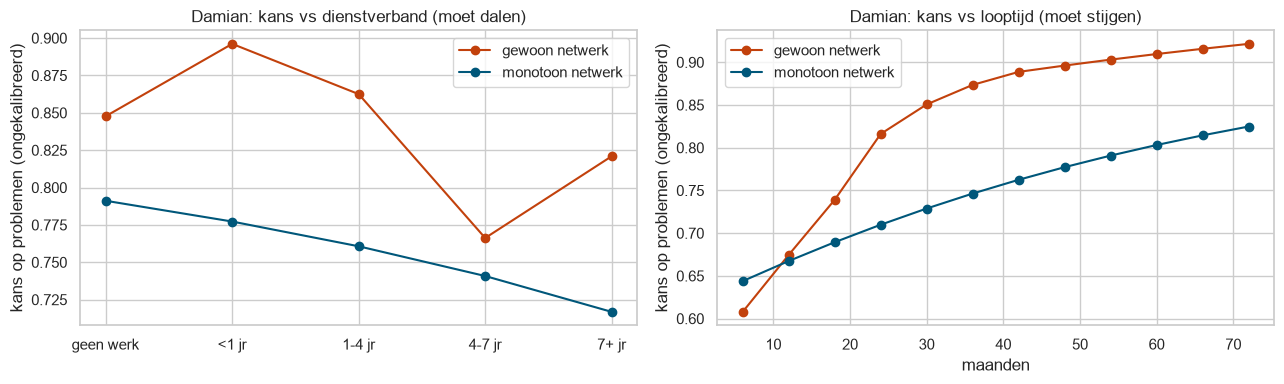

In [11]:
from sklearn.model_selection import train_test_split as _tts
Xtr_, Xte_, ytr_, yte_ = _tts(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
F = SCHULDWIJZER_FEATURES
plain = make_pipeline(F, mlp(hidden_layer_sizes=(8,), alpha=1.0)).fit(Xtr_[F], ytr_)
mono = MonotoneNNClassifier(F, hidden=4, alpha=0.01).fit(Xtr_[F], ytr_)
from ml.config import to_model_row
base = {f: DAMIAN[f] for f in F}
emp = ['unemployed', '<1', '1<=X<4', '4<=X<7', '>=7']
dur = list(range(6, 73, 6))
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for model, name, color in [(plain, 'gewoon netwerk', RISK), (mono, 'monotoon netwerk', ACC)]:
    pe = model.predict_proba(pd.DataFrame([to_model_row({**base, 'employment': e}, F) for e in emp]))[:, 1]
    pdur = model.predict_proba(pd.DataFrame([to_model_row({**base, 'duration': d}, F) for d in dur]))[:, 1]
    axes[0].plot(['geen werk', '<1 jr', '1-4 jr', '4-7 jr', '7+ jr'], pe, 'o-', color=color, label=name)
    axes[1].plot(dur, pdur, 'o-', color=color, label=name)
axes[0].set_title('Damian: kans vs dienstverband (moet dalen)'); axes[1].set_title('Damian: kans vs looptijd (moet stijgen)')
axes[1].set_xlabel('maanden')
for a in axes: a.legend(); a.set_ylabel('kans op problemen (ongekalibreerd)')
plt.tight_layout(); plt.show()

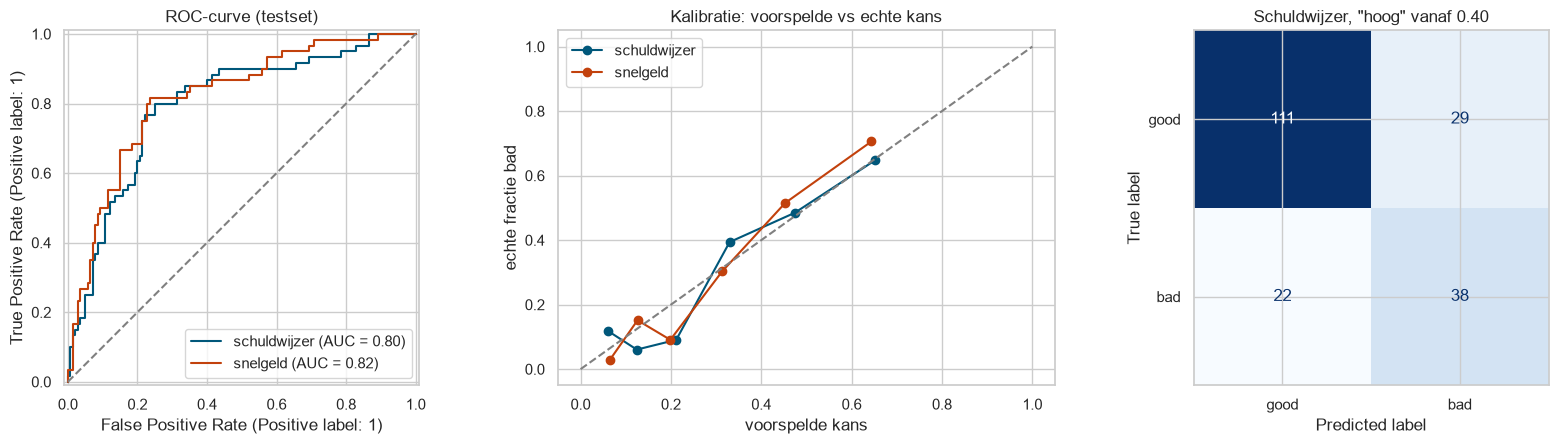

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.calibration import CalibratedClassifierCV, calibration_curve
from sklearn.metrics import RocCurveDisplay, ConfusionMatrixDisplay

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))
for app, feats, color in [('schuldwijzer', SCHULDWIJZER_FEATURES, ACC), ('snelgeld', SNELGELD_FEATURES, RISK)]:
    bp = metrics[app]['best_params']
    m = CalibratedClassifierCV(MonotoneNNClassifier(feats, random_state=RANDOM_STATE, **bp), method='sigmoid', cv=5, ensemble=False).fit(X_tr[feats], y_tr)
    p = m.predict_proba(X_te[feats])[:, 1]
    RocCurveDisplay.from_predictions(y_te, p, name=app, ax=axes[0], color=color)
    frac, mean = calibration_curve(y_te, p, n_bins=6, strategy='quantile')
    axes[1].plot(mean, frac, 'o-', color=color, label=app)
    if app == 'schuldwijzer':
        t = metrics[app]['thresholds']['hoog_vanaf']
        ConfusionMatrixDisplay.from_predictions(y_te, (p >= t).astype(int), display_labels=['good', 'bad'],
                                                ax=axes[2], cmap='Blues', colorbar=False)
        axes[2].set_title(f'Schuldwijzer, "hoog" vanaf {t:.2f}')
axes[0].plot([0, 1], [0, 1], ls='--', color='grey'); axes[0].set_title('ROC-curve (testset)')
axes[1].plot([0, 1], [0, 1], ls='--', color='grey'); axes[1].set_title('Kalibratie: voorspelde vs echte kans')
axes[1].set_xlabel('voorspelde kans'); axes[1].set_ylabel('echte fractie bad'); axes[1].legend()
plt.tight_layout(); plt.show()

## 6. Precision of recall? De drempel van Schuldwijzer

Wat is erger voor Damian?

- **Vals alarm (false positive):** Schuldwijzer waarschuwt, terwijl hij het had gered. Gevolg: hij praat met een schuldhulpverlener of leent iets minder. Vervelend, maar onschuldig.
- **Gemiste waarschuwing (false negative):** Schuldwijzer zegt "lijkt goed te dragen" en hij komt jaren in de schulden.

Schuldwijzer optimaliseert daarom op **recall** voor "bad". We delen de kans in drie groepen in, met grenzen die zijn bepaald op out-of-fold voorspellingen:

- "hoog" vangt 60% van alle probleemgevallen;
- "gemiddeld" of "hoog" samen vangen 90%.

Drie groepen zijn bovendien beter te begrijpen dan één kale kans (AI-UX: *confidence*).

In [13]:
pd.DataFrame(metrics['schuldwijzer']['bands'])

,band,van,tot,aandeel,werkelijk_bad
0,laag,0.0000,0.1508,0.343,0.087
1,gemiddeld,0.1508,0.3968,0.333,0.270
2,hoog,0.3968,1.0000,0.324,0.556


In de groep 'hoog' kreeg 56% echt betalingsproblemen, in 'laag' 9%. De app toont daarnaast per aanvraag een **marge** (spreiding van een bootstrap-ensemble) en een **frequentie**: van de 100 eerdere aanvragers met de dichtstbijzijnde out-of-fold kans, hoeveel kregen er echt problemen. Omdat het model gekalibreerd is, ligt dat getal dicht bij de kans zelf. Dat voorkomt de verwarring van twee verschillende percentages.

## 7. Fairness-audit

Hoe vaak komt elke groep in 'hoog' terecht (geflagd), en hoe vaak is dat een vals alarm (FPR: aandeel van de mensen die netjes afbetaalden)? Gemeten op **alle 1000 aanvragen**, elk voorspeld door een model dat die aanvraag niet zag (out-of-fold), bij de grens die de app gebruikt.

In [14]:
rows = []
for app in ['schuldwijzer', 'snelgeld']:
    for kenmerk, groups in metrics[app]['fairness'].items():
        for g, r in groups.items():
            rows.append({'app': app, 'kenmerk': kenmerk, 'groep': g, **r})
fair = pd.DataFrame(rows)
fair.pivot_table(index=['kenmerk', 'groep'], columns='app', values=['n', 'n_good', 'werkelijk_bad', 'gemiddelde_kans', 'geflagd', 'fpr']).round(3)

fpr               geflagd           \
app                            schuldwijzer snelgeld schuldwijzer snelgeld   
kenmerk       groep                                                          
geslacht      man                     0.208    0.176        0.313    0.280   
              vrouw                   0.199    0.249        0.348    0.403   
leeftijd      25 of jonger            0.264    0.318        0.400    0.468   
              ouder dan 25            0.195    0.175        0.306    0.283   
nationaliteit buitenlands             0.205    0.204        0.326    0.326   
              niet buitenlands        0.212    0.061        0.270    0.108   

                               gemiddelde_kans                     n           \
app                               schuldwijzer snelgeld schuldwijzer snelgeld   
kenmerk       groep                                                             
geslacht      man                        0.296    0.278        690.0    690.0   
              vrouw                      0.310    0.351        310.0    310.0   
leeftijd      25 of jonger               0.351    0.391        190.0    190.0   
              ouder dan 25               0.288    0.279        810.0    810.0   
nationaliteit buitenlands                0.301    0.304        963.0    963.0   
              niet buitenlands           0.283    0.199         37.0     37.0   

                                     n_good          werkelijk_bad           
app                            schuldwijzer snelgeld  schuldwijzer snelgeld  
kenmerk       groep                                                          
geslacht      man                     499.0    499.0         0.277    0.277  
              vrouw                   201.0    201.0         0.352    0.352  
leeftijd      25 of jonger            110.0    110.0         0.421    0.421  
              ouder dan 25            590.0    590.0         0.272    0.272  
nationaliteit buitenlands             667.0    667.0         0.307    0.307  
              niet buitenlands         33.0     33.0         0.108    0.108

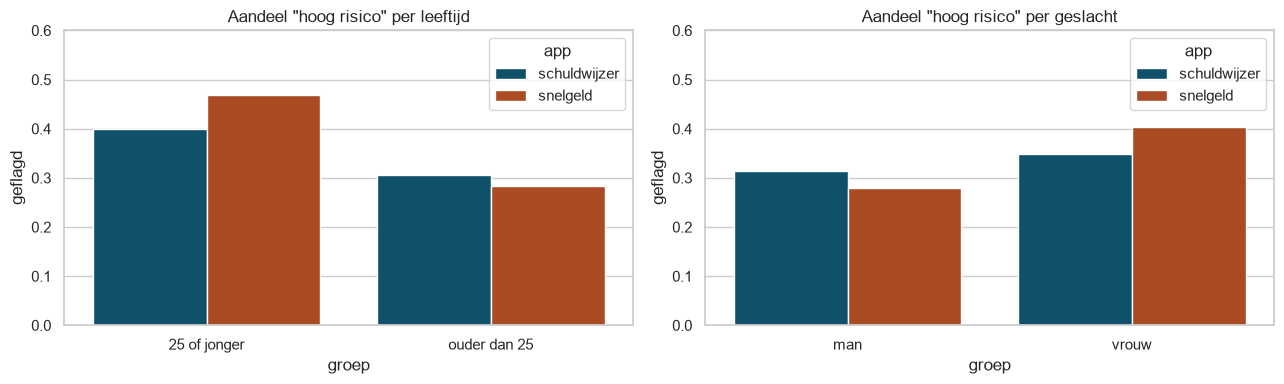

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, kenmerk in zip(axes, ['leeftijd', 'geslacht']):
    d = fair[fair.kenmerk == kenmerk]
    sns.barplot(data=d, x='groep', y='geflagd', hue='app', ax=ax, palette={'schuldwijzer': ACC, 'snelgeld': RISK})
    ax.set_title(f'Aandeel "hoog risico" per {kenmerk}'); ax.set_ylim(0, 0.6)
plt.tight_layout(); plt.show()

**Wat we zien, eerlijk benoemd:**

- **Geslacht:** Schuldwijzer behandelt mannen en vrouwen vrijwel gelijk (31% tegen 35% in 'hoog', vals alarm 21% tegen 20%). SnelGeld, dat geslacht direct gebruikt, flagt vrouwen veel vaker (40% tegen 28%) en geeft hen vaker vals alarm (25% tegen 18%).
- **Leeftijd, proxy-bias:** ook zonder leeftijd flagt Schuldwijzer jongeren vaker (40% tegen 31%), en ze krijgen vaker **onterecht** een waarschuwing (26% tegen 20%). Kenmerken als dienstverband, woonsituatie en spaargeld hangen samen met leeftijd. Kenmerken weglaten is dus nodig, maar niet genoeg. Het verschil is half zo groot als bij SnelGeld (32% tegen 18%).
- **Ons oordeel:** omdat Schuldwijzer waarschuwt en niets weigert of duurder maakt, vinden we dit verdedigbaar, maar het blijft een nadeel (onnodig ontmoedigen). Bij een app die leningen toekent, zou hetzelfde verschil onacceptabel zijn.
- **Voorbehoud:** 190 jongeren, van wie 110 netjes afbetaalden; de groep "niet buitenlands" is met 37 te klein voor conclusies.

## 8. Explainability: globaal en lokaal

**Globaal (permutation importance):** hoeveel slechter wordt de AUC als we één feature door elkaar husselen? Dit staat in de app onder *Hoe het werkt*.

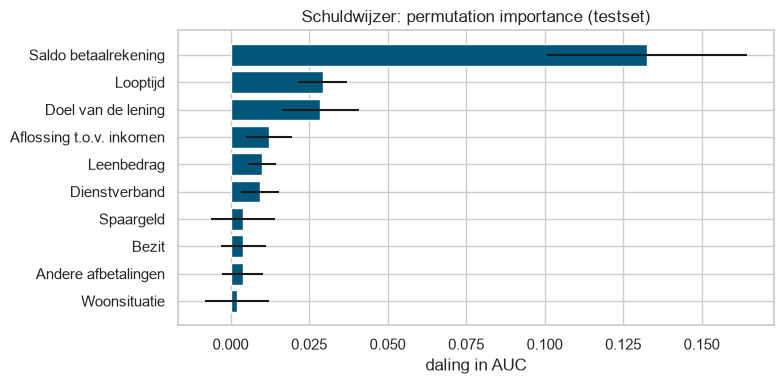

In [16]:
imp = pd.DataFrame(metrics['schuldwijzer']['importance'])
imp['label'] = imp['feature'].map(lambda f: FEATURES[f]['short'])
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(imp['label'][::-1], imp['mean'][::-1], xerr=imp['std'][::-1], color=ACC)
ax.set_xlabel('daling in AUC'); ax.set_title('Schuldwijzer: permutation importance (testset)')
plt.tight_layout(); plt.show()

**Lokaal (exacte Shapley-waarden):** waarom krijgt *deze* persoon *deze* uitkomst? Voor elke subset van de 10 features rekenen we de gemiddelde voorspelling uit, met de overige features uit een achtergrondsteekproef van 40 aanvragen. Met 10 features zijn dat 2^10 = 1024 subsets: klein genoeg om exact te rekenen in plaats van te benaderen (zoals SHAP's KernelExplainer). Dit kost ongeveer 30 ms per aanvraag. De bijdragen tellen precies op tot de voorspelling.

In [17]:
P = Predictor(joblib.load(ROOT / 'models' / 'schuldwijzer.joblib'))
damian = {f: DAMIAN[f] for f in SCHULDWIJZER_FEATURES}
s = P.shapley(damian)
print(f"basis (gemiddelde aanvrager): {s['base']:.3f}")
print(f"basis + som bijdragen:        {s['base'] + sum(s['phi'].values()):.3f}")
print(f"voorspelling model:           {P.proba(damian):.3f}")
ex = pd.DataFrame(P.explain(damian))[['label', 'value_label', 'contribution']]
ex

basis (gemiddelde aanvrager): 0.311
basis + som bijdragen:        0.750
voorspelling model:           0.750


,label,value_label,contribution
0,Doel van de lening,Tweedehands auto,-0.1226
1,Looptijd,48 maanden,0.1003
2,Andere afbetalingen,"Ja, bij een winkel of achteraf betalen",0.0894
3,Saldo betaalrekening,Tussen € 0 en € 100,0.0872
4,Woonsituatie,Ik huur,0.0761
5,Bezit,Geen noemenswaardig bezit,0.0636
6,Dienstverband,Korter dan 1 jaar,0.0410
7,Spaargeld,Minder dan € 50,0.0401
8,Aflossing t.o.v. inkomen,35% of meer,0.0401
9,Leenbedrag,€ 3.000,0.0233


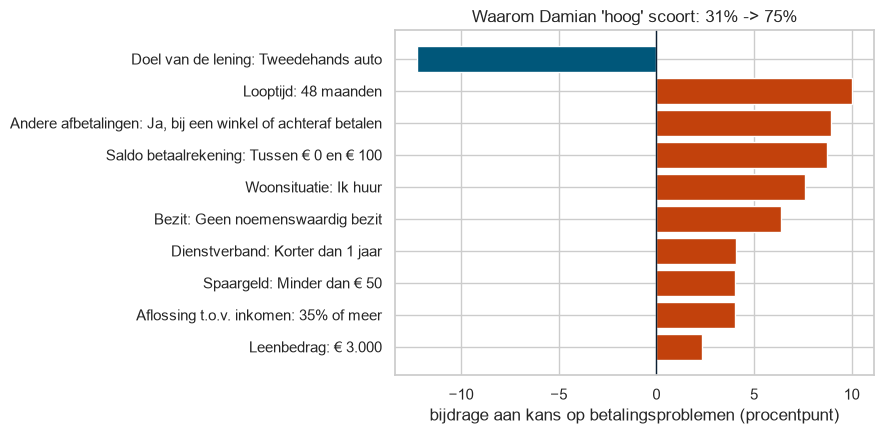

In [18]:
fig, ax = plt.subplots(figsize=(9, 4.5))
e = ex.iloc[::-1]
ax.barh(e['label'] + ': ' + e['value_label'], e['contribution'] * 100,
        color=[RISK if c > 0 else ACC for c in e['contribution']])
ax.axvline(0, color=INK, lw=1)
ax.set_xlabel('bijdrage aan kans op betalingsproblemen (procentpunt)')
ax.set_title(f"Waarom Damian 'hoog' scoort: {s['base']:.0%} -> {P.proba(damian):.0%}")
plt.tight_layout(); plt.show()

## 9. Wat verlaagt het risico? (counterfactuals)

Uitleg wordt pas bruikbaar als je weet wat je kunt doen (AI-UX: *control*). Schuldwijzer zoekt daarom twee soorten alternatieven:

- **Aan de lening:** bedrag en looptijd, maar alleen opties waarbij het maandbedrag niet stijgt. Het model houdt "aflossing t.o.v. inkomen" vast, waardoor een kortere looptijd anders onterecht gratis zou lijken.
- **Aan je situatie, op termijn:** de eerstvolgende haalbare stap in spaargeld, saldo of lopende afbetalingen.

In [19]:
pd.DataFrame(P.counterfactuals(damian)), pd.DataFrame(P.levers(damian))

(   credit_amount  duration  probability  band  verschil
 0         2250.0        36       0.6968  hoog   -0.0529,
                feature                 label  \
 0  other_payment_plans   Andere afbetalingen   
 1      checking_status  Saldo betaalrekening   
 2       savings_status             Spaargeld   
 
                                      from              to  probability  band  \
 0  Ja, bij een winkel of achteraf betalen             Nee       0.6556  hoog   
 1                     Tussen € 0 en € 100  Meer dan € 100       0.6797  hoog   
 2                         Minder dan € 50  € 50 tot € 250       0.7132  hoog   
 
    verschil  
 0   -0.0941  
 1   -0.0700  
 2   -0.0364  )

Voor Damian helpt aan de lening schuiven weinig: zijn situatie (weinig buffer, kort in dienst, al een afbetaling bij een winkel) weegt zwaarder. De app zegt dat ook eerlijk. Ze stelt nooit een langere looptijd voor, want meer rente en een langere schuld zijn geen bescherming.

## 10. SnelGeld: dezelfde voorspelling, omgezet in winst

De prijslogica staat in `backend/app/pricing.py`. Rente = basis + risico-opslag (uit het model) + haast-opslag + leeftijdsopslag + opslag op nationaliteit. Hoog risico krijgt daarnaast 50% méér geld aangeboden.

In [20]:
from backend.app.pricing import offer
S = Predictor(joblib.load(ROOT / 'models' / 'snelgeld.joblib'))
hoog = S.meta['thresholds']['hoog_vanaf']
scen = {
    'Damian (24, haast)': ({**DAMIAN}, 'vandaag'),
    'Damian zonder haast': ({**DAMIAN}, 'geen_haast'),
    'Zelfde profiel, 40 jaar': ({**DAMIAN, 'age': 40}, 'geen_haast'),
    'Zelfde profiel, buitenlandse nationaliteit': ({**DAMIAN, 'foreign_worker': 'yes'}, 'vandaag'),
    'Zelfde profiel, vrouw': ({**DAMIAN, 'personal_status': 'female div/dep/mar'}, 'vandaag'),
}
rows = []
for name, (v, u) in scen.items():
    p = S.proba(v); o = offer(v, p, u, hoog)
    rows.append({'scenario': name, 'kans bad (model)': round(p, 3), 'rente %': o['apr'],
                 'aangeboden': o['upsell_amount'], 'looptijd': o['months'],
                 'maandbedrag': o['monthly'], 'totaal terug': o['total']})
pd.DataFrame(rows)

,scenario,kans bad (model),rente %,aangeboden,looptijd,maandbedrag,totaal terug
0,"Damian (24, haast)",0.525,24.8,4500,72,80.44,5940.95
1,Damian zonder haast,0.525,20.8,4500,72,73.26,5423.46
2,"Zelfde profiel, 40 jaar",0.457,18.1,4500,72,68.59,5087.70
3,"Zelfde profiel, buitenlandse nationaliteit",0.655,28.2,4500,72,86.80,6398.62
4,"Zelfde profiel, vrouw",0.618,26.5,4500,72,83.59,6167.81


Zelfde persoon, zelfde lening: alleen door geslacht, leeftijd, nationaliteit of haast betaalt hij of zij tientallen tot honderden euro's meer. En het model voorspelt bij Damian een verhoogd risico op betalingsproblemen, maar SnelGeld toont "Goedgekeurd · 98% match". De wettelijke maximale rente in Nederland is sinds 1 januari 2026 **12%**; SnelGeld rekent het dubbele.

## 11. Conclusie

- Een klein, gekalibreerd **monotoon neuraal netwerk** voorspelt kredietrisico met een AUC van 0,80 (Schuldwijzer) tot 0,82 (SnelGeld) op ongeziene data. Dat is minstens zo goed als logistische regressie en een gewoon netwerk, en het maakt als enige **geen onlogische sprongen**.
- **Dataminimalisatie en het weglaten van beschermde kenmerken kosten vrijwel geen nauwkeurigheid.** Schuldwijzer vraagt 10 gegevens; SnelGeld vraagt er meer dan 20, plus naam, e-mail, telefoon en toestemming voor contacten en locatie.
- **Bias verdwijnt niet door kenmerken weg te laten** (proxy-bias bij leeftijd). Daarom meten we het, en tonen we het eerlijk in de app.
- **Explainability** is in Schuldwijzer een recht van de gebruiker (exacte Shapley-uitleg plus alternatieven). In SnelGeld wordt dezelfde kennis verborgen en tegen de gebruiker ingezet.
- Het verschil tussen goed en kwaad zit niet in het model, maar in **wat je met de voorspelling doet**: beschermen of uitbuiten.